# Notebook 09: Final Model Evaluation

## Objective
Evaluate the final selected models on the untouched test dataset.

## Models
1. Baseline Random Forest
2. Tuned Random Forest
3. Best ISFR model
4. Adapted ISFE ensemble

## Evaluation metrics
- Accuracy
- Macro F1-score
- Balanced Accuracy
- Fraud Precision
- Fraud Recall
- Fraud F1-score

The test dataset is used only for final evaluation.

In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

print("Imports successful.")

Imports successful.


In [2]:
PROJECT_DIR = os.path.dirname(os.getcwd())

PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
REPORTS_DIR = os.path.join(PROJECT_DIR, "reports")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(REPORTS_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /Users/jasmithav/isfe_creditcard_project


In [3]:
X_test = pd.read_csv(
    os.path.join(PROCESSED_DIR, "X_test.csv")
).values

y_test = pd.read_csv(
    os.path.join(PROCESSED_DIR, "y_test.csv")
).values.ravel()

print("Test features:", X_test.shape)
print("Test legitimate cases:", np.sum(y_test == 0))
print("Test fraud cases:", np.sum(y_test == 1))

Test features: (56961, 30)
Test legitimate cases: 56863
Test fraud cases: 98


In [4]:
print("Available model files:\n")

for filename in sorted(os.listdir(MODELS_DIR)):
    if filename.endswith(".joblib"):
        print(filename)

Available model files:

decision_tree.joblib
isfe_cluster_model.joblib
isfr_best_model.joblib
linear_svm.joblib
random_forest.joblib
subset_1_isfe.joblib
subset_2_isfe.joblib
subset_3_isfe.joblib
tuned_random_forest.joblib
voting_ensemble.joblib


In [5]:
# Load baseline and tuned models
baseline_rf = joblib.load(
    os.path.join(MODELS_DIR, "random_forest.joblib")
)

tuned_rf = joblib.load(
    os.path.join(MODELS_DIR, "tuned_random_forest.joblib")
)

# Load ISFR model
isfr_model = joblib.load(
    os.path.join(MODELS_DIR, "isfr_best_model.joblib")
)

# Load ISFE ensemble members
isfe_models = [
    joblib.load(os.path.join(MODELS_DIR, "subset_1_isfe.joblib")),
    joblib.load(os.path.join(MODELS_DIR, "subset_2_isfe.joblib")),
    joblib.load(os.path.join(MODELS_DIR, "subset_3_isfe.joblib"))
]

# Load preprocessing objects used for PCA views
SFR_DIR = os.path.join(PROCESSED_DIR, "sfr")

scaler = joblib.load(
    os.path.join(SFR_DIR, "scaler.joblib")
)

pca = joblib.load(
    os.path.join(SFR_DIR, "pca.joblib")
)

print("All models and preprocessing objects loaded.")

print("Baseline model:", type(baseline_rf).__name__)
print("Tuned model:", type(tuned_rf).__name__)
print("ISFR model:", type(isfr_model).__name__)
print("ISFE ensemble members:", len(isfe_models))
print("PCA components:", pca.n_components_)

All models and preprocessing objects loaded.
Baseline model: RandomForestClassifier
Tuned model: RandomForestClassifier
ISFR model: RandomForestClassifier
ISFE ensemble members: 3
PCA components: 27


In [8]:
# Load test data with original column names
X_test_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "X_test.csv")
)

# Apply training-fitted scaler and PCA
X_test_scaled = scaler.transform(X_test_df)
X_test_pca = pca.transform(X_test_scaled)

X_test_original = X_test_df.values

print("Original test shape:", X_test_original.shape)
print("PCA test shape:", X_test_pca.shape)

assert X_test_pca.shape == (56961, 27)
assert np.isfinite(X_test_pca).all()

print("Test transformation successful.")

Original test shape: (56961, 30)
PCA test shape: (56961, 27)
Test transformation successful.


In [9]:
def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Fraud Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Fraud Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Fraud F1": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

print("Evaluation function ready.")

Evaluation function ready.


In [12]:
# Helper function to handle feature-name compatibility
def predict_compatible(model, X_df):
    if hasattr(model, "feature_names_in_"):
        return model.predict(X_df)

    return model.predict(X_df.to_numpy())


# 1. Baseline Random Forest
baseline_predictions = predict_compatible(
    baseline_rf,
    X_test_df
)

# 2. Tuned Random Forest
tuned_predictions = predict_compatible(
    tuned_rf,
    X_test_df
)

# 3. ISFR model (27 PCA features)
isfr_predictions = isfr_model.predict(
    X_test_pca
)

# 4. ISFE ensemble (27 PCA features)
isfe_member_predictions = np.array([
    model.predict(X_test_pca)
    for model in isfe_models
])

# Hard voting: fraud if at least 2 of 3 models predict fraud
isfe_predictions = (
    np.sum(isfe_member_predictions, axis=0) >= 2
).astype(int)


# Display prediction counts
print("All test predictions generated.\n")

predictions_dict = {
    "Baseline Random Forest": baseline_predictions,
    "Tuned Random Forest": tuned_predictions,
    "ISFR Adaptation": isfr_predictions,
    "ISFE Adaptation": isfe_predictions
}

for name, predictions in predictions_dict.items():
    print(
        f"{name}: "
        f"Legitimate = {np.sum(predictions == 0)}, "
        f"Fraud = {np.sum(predictions == 1)}"
    )

# Verify prediction dimensions
for name, predictions in predictions_dict.items():
    assert len(predictions) == len(y_test), (
        f"Prediction length mismatch: {name}"
    )

print("\nAll prediction dimensions verified.")

All test predictions generated.

Baseline Random Forest: Legitimate = 56882, Fraud = 79
Tuned Random Forest: Legitimate = 56880, Fraud = 81
ISFR Adaptation: Legitimate = 56899, Fraud = 62
ISFE Adaptation: Legitimate = 56262, Fraud = 699

All prediction dimensions verified.


In [13]:
# Calculate metrics for all models
final_results = []

for model_name, predictions in predictions_dict.items():

    metrics = {
        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Macro F1": f1_score(
            y_test,
            predictions,
            average="macro"
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test,
            predictions
        ),

        "Fraud Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Fraud Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Fraud F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    }

    final_results.append({
        "Model": model_name,
        **metrics
    })


# Create final comparison table
final_results_df = pd.DataFrame(final_results)

print("FINAL TEST RESULTS\n")

display(
    final_results_df.round(6)
)


# Save results
results_path = os.path.join(
    REPORTS_DIR,
    "final_test_results.csv"
)

final_results_df.to_csv(
    results_path,
    index=False
)

print("\nFinal test results saved to:")
print(results_path)

FINAL TEST RESULTS



,Model,Accuracy,Macro F1,Balanced Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,Baseline Random Forest,0.999561,0.929269,0.887729,0.962025,0.775510,0.858757
1,Tuned Random Forest,0.999526,0.924462,0.887711,0.938272,0.775510,0.849162
2,ISFR Adaptation,0.999298,0.874824,0.806105,0.967742,0.612245,0.750000
3,ISFE Adaptation,0.989168,0.610196,0.953829,0.128755,0.918367,0.225847



Final test results saved to:
/Users/jasmithav/isfe_creditcard_project/reports/final_test_results.csv


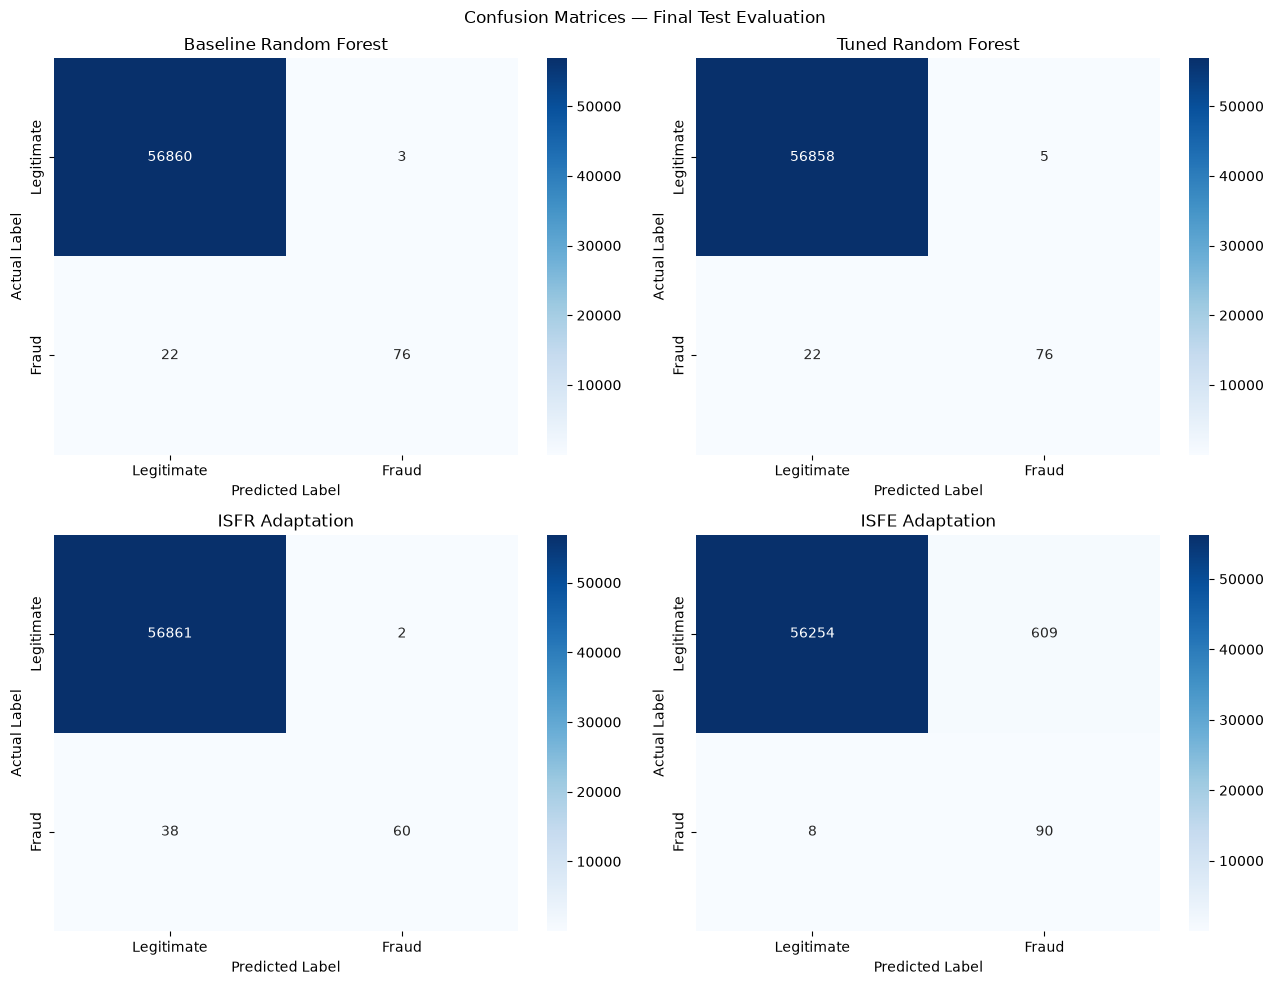

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (model_name, predictions) in zip(
    axes.flatten(), predictions_dict.items()
):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrices — Final Test Evaluation")
plt.tight_layout()

plt.savefig(
    os.path.join(REPORTS_DIR, "final_confusion_matrices.png"),
    dpi=300
)

plt.show()

In [15]:
for model_name, predictions in predictions_dict.items():

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=["Legitimate", "Fraud"],
            zero_division=0
        )
    )


Baseline Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56863
       Fraud       0.96      0.78      0.86        98

    accuracy                           1.00     56961
   macro avg       0.98      0.89      0.93     56961
weighted avg       1.00      1.00      1.00     56961


Tuned Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56863
       Fraud       0.94      0.78      0.85        98

    accuracy                           1.00     56961
   macro avg       0.97      0.89      0.92     56961
weighted avg       1.00      1.00      1.00     56961


ISFR Adaptation
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56863
       Fraud       0.97      0.61      0.75        98

    accuracy                           1.00     56961
   macro avg       0.98      0.81      0.87     56961
weighted avg

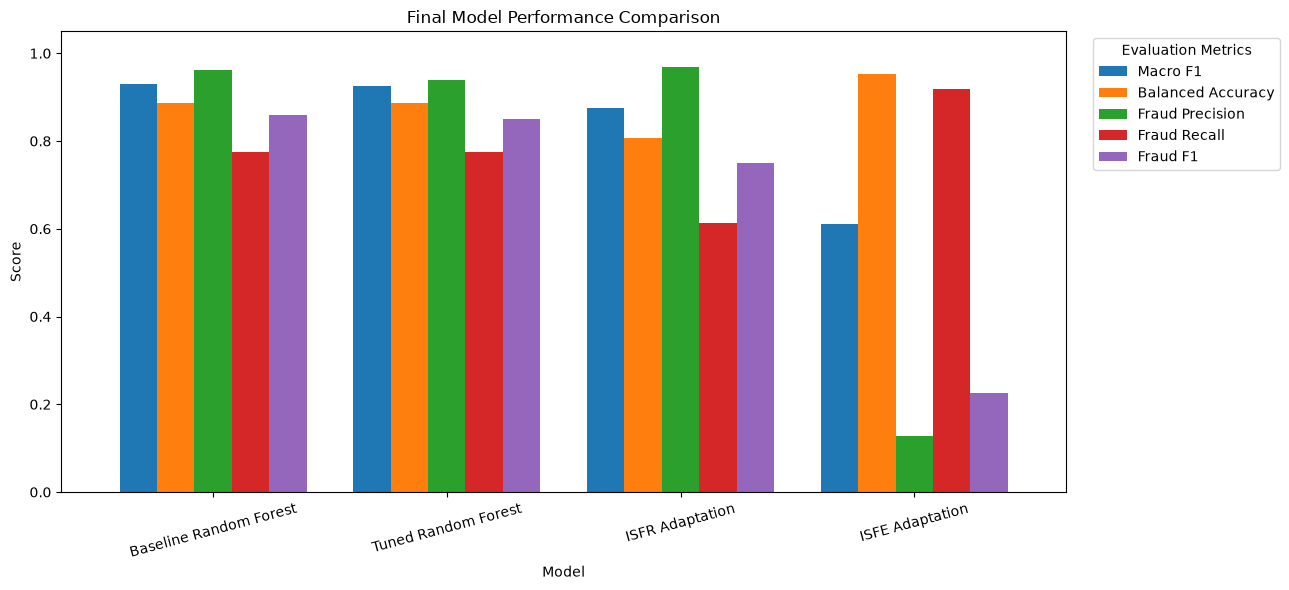

In [16]:
metrics_to_plot = [
    "Macro F1",
    "Balanced Accuracy",
    "Fraud Precision",
    "Fraud Recall",
    "Fraud F1"
]

plot_df = final_results_df.set_index("Model")[metrics_to_plot]

ax = plot_df.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Final Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=15)

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    os.path.join(REPORTS_DIR, "final_model_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
summary = {
    "Dataset": "Credit Card Fraud Detection",
    "Test Samples": len(y_test),
    "Test Fraud Cases": int(np.sum(y_test == 1)),
    "Test Legitimate Cases": int(np.sum(y_test == 0)),
    "Best Overall Model": "Baseline Random Forest",
    "Best Macro F1": float(
        final_results_df.loc[
            final_results_df["Macro F1"].idxmax(),
            "Macro F1"
        ]
    ),
    "Highest Fraud Recall Model": "ISFE Adaptation",
    "Highest Fraud Recall": float(
        final_results_df["Fraud Recall"].max()
    )
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Parameter", "Value"]
)

display(summary_df)

summary_df.to_csv(
    os.path.join(REPORTS_DIR, "final_experiment_summary.csv"),
    index=False
)

print("Final experiment summary saved.")

,Parameter,Value
0,Dataset,Credit Card Fraud Detection
1,Test Samples,56961
2,Test Fraud Cases,98
3,Test Legitimate Cases,56863
4,Best Overall Model,Baseline Random Forest
5,Best Macro F1,0.929269
6,Highest Fraud Recall Model,ISFE Adaptation
7,Highest Fraud Recall,0.918367


Final experiment summary saved.
